In [1]:
%%writefile ../src/kpis.py
"""KPI and diagnostic helpers. Reused by notebooks and the Streamlit app."""
import numpy as np
import pandas as pd
from src import config


def group_summary(d: pd.DataFrame, by: str) -> pd.DataFrame:
    """Orders, late rate, on-time rate and average delay gap per group."""
    g = d.groupby(by).agg(
        orders=(config.GAP, "size"),
        late_rate=(config.TARGET, "mean"),
        avg_gap=(config.GAP, "mean"),
    )
    g["on_time_rate"] = 1 - g["late_rate"]
    return g.round(4)


def mode_adjusted(d: pd.DataFrame, by: str) -> pd.DataFrame:
    """Is a group later than its shipping-mode mix would predict?

    expected_rate = late rate the group would have if each of its orders were as
    late as the average order of the same shipping mode.
    z = (observed - expected) / standard error. |z| above ~3 is hard to explain
    by chance; with many groups a few |z| near 2 are normal.
    """
    p = d.groupby(config.SHIP_MODE)[config.TARGET].transform("mean")
    t = d.assign(_p=p, _v=p * (1 - p))
    g = t.groupby(by).agg(orders=(config.TARGET, "size"),
                          obs=(config.TARGET, "sum"),
                          exp=("_p", "sum"), var=("_v", "sum"))
    out = pd.DataFrame({
        "orders": g["orders"],
        "observed_rate": g["obs"] / g["orders"],
        "expected_rate": g["exp"] / g["orders"],
        "z": (g["obs"] - g["exp"]) / np.sqrt(g["var"]),
    })
    return out.round(4).sort_values("z")

Overwriting ../src/kpis.py


In [2]:
import sys
sys.path.append("..")
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config
from src.data import delivered_only
from src.kpis import group_summary, mode_adjusted

pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

df = pd.read_parquet(config.PROCESSED_PATH)
d = delivered_only(df)          # 172,765 delivered orders
print(d.shape)

(172765, 38)


In [3]:
print(d[config.GAP].value_counts().sort_index())
print()
print(pd.crosstab(d[config.SHIP_MODE], d[config.REAL_DAYS]))
print()
print(pd.crosstab(d[config.SHIP_MODE], d[config.GAP]))

delay_gap
-2    20873
-1    20719
 0    32196
 1    57957
 2    27551
 3     6772
 4     6697
Name: count, dtype: int64

Days for shipping (real)     0     1      2      3      4      5      6
Shipping Mode                                                          
First Class                  0     0  26513      0      0      0      0
Same Day                  4839  4454      0      0      0      0      0
Second Class                 0     0   6819   6759   6759   6772   6697
Standard Class               0     0  20873  20719  20538  20231  20792

delay_gap          -2     -1      0      1      2     3     4
Shipping Mode                                                
First Class         0      0      0  26513      0     0     0
Same Day            0      0   4839   4454      0     0     0
Second Class        0      0   6819   6759   6759  6772  6697
Standard Class  20873  20719  20538  20231  20792     0     0


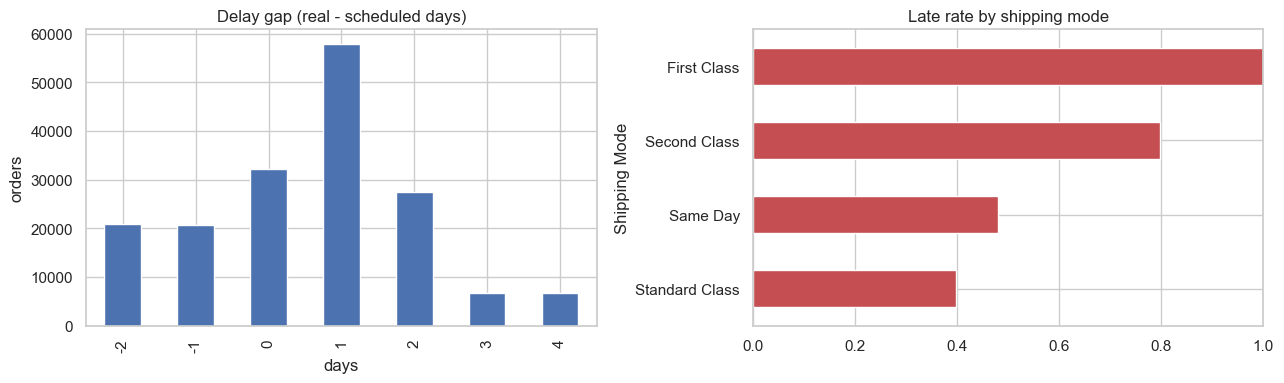

,orders,late_rate,avg_gap,on_time_rate
Shipping Mode,,,,
Standard Class,103153,0.3977,-0.0063,0.6023
Same Day,9293,0.4793,0.4793,0.5207
Second Class,33806,0.7983,1.9932,0.2017
First Class,26513,1.0000,1.0000,0.0000


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

d[config.GAP].value_counts().sort_index().plot.bar(ax=ax[0], color="#4c72b0")
ax[0].set_title("Delay gap (real - scheduled days)")
ax[0].set_xlabel("days"); ax[0].set_ylabel("orders")

m = group_summary(d, config.SHIP_MODE).sort_values("late_rate")
m["late_rate"].plot.barh(ax=ax[1], color="#c44e52")
ax[1].set_title("Late rate by shipping mode"); ax[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig("../reports/figures/gap_and_mode.png", dpi=150)
plt.show()
m

In [5]:
print(group_summary(d, config.MARKET).sort_values("late_rate"))
print()
print(group_summary(d, config.SEGMENT).sort_values("late_rate"))

              orders  late_rate  avg_gap  on_time_rate
Market                                                
Africa         11154     0.5684   0.5620        0.4316
LATAM          49309     0.5687   0.5544        0.4313
Pacific Asia   39585     0.5738   0.5695        0.4262
USCA           24627     0.5741   0.5752        0.4259
Europe         48090     0.5769   0.5695        0.4231

                  orders  late_rate  avg_gap  on_time_rate
Customer Segment                                          
Corporate          52528     0.5708   0.5572        0.4292
Consumer           89420     0.5731   0.5658        0.4269
Home Office        30817     0.5759   0.5788        0.4241


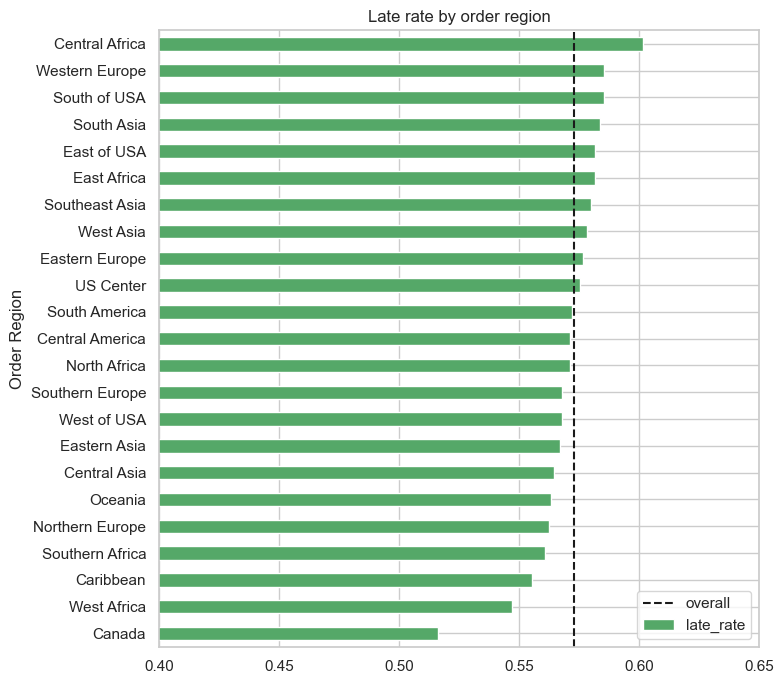

In [6]:
r = group_summary(d, config.REGION).sort_values("late_rate")
fig, ax = plt.subplots(figsize=(8, 7))
r["late_rate"].plot.barh(ax=ax, color="#55a868")
ax.axvline(d[config.TARGET].mean(), color="k", ls="--", label="overall")
ax.set_xlim(0.4, 0.65); ax.legend(); ax.set_title("Late rate by order region")
plt.tight_layout()
plt.savefig("../reports/figures/region_late_rate.png", dpi=150)
plt.show()

In [7]:
for col in [config.MARKET, config.SEGMENT]:
    print(mode_adjusted(d, col), "\n")

reg = mode_adjusted(d, config.REGION)
print(reg.head(4), "\n...\n", reg.tail(4))

              orders  observed_rate  expected_rate       z
Market                                                    
LATAM          49309         0.5687         0.5703 -0.7958
USCA           24627         0.5741         0.5755 -0.5188
Africa         11154         0.5684         0.5679  0.1285
Pacific Asia   39585         0.5738         0.5725  0.5847
Europe         48090         0.5769         0.5757  0.5864 

                  orders  observed_rate  expected_rate       z
Customer Segment                                              
Corporate          52528         0.5708         0.5732 -1.2923
Home Office        30817         0.5759         0.5759  0.0012
Consumer           89420         0.5731         0.5717  0.9898 

              orders  observed_rate  expected_rate       z
Order Region                                              
Canada           907         0.5160         0.5812 -4.6090
Caribbean       7951         0.5553         0.5658 -2.1548
US Center       5653         0.5